# Week 2 Day 1: EDA on the LangGraph Pipeline Dataset

## EDA Summary
- The dataset has 6 rows and 7 columns; it defines the research → summarise → critique loop, one row per edge.
- Only 3 columns are numeric or boolean (`step_id`, `max_retries`, `requires_approval`); the rest are text.
- `max_retries` ranges from 0 to 3 (mean 1.5); the critique steps carry the highest value (3).
- The target `requires_approval` is imbalanced: 5 rows are False and 1 is True (only `send_report`).
- No column has missing values (0% everywhere); strongest correlation is `step_id` vs `requires_approval` (0.65), but with 6 rows this is not reliable.

In [3]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

candidates = [Path("data/sample_dataset.csv"), Path("../data/sample_dataset.csv")]
csv_path = next((p for p in candidates if p.exists()), None)
if csv_path is None:
    import os
    raise FileNotFoundError(f"CSV not found. Current folder is: {os.getcwd()}")

df = pd.read_csv(csv_path)
df

,step_id,node,description,next_node,condition,max_retries,requires_approval
0,1,start,Receive the user question,research,always,0,False
1,2,research,Gather facts on the topic,summarise,always,2,False
2,3,summarise,Condense the notes into a short summary,critique,always,1,False
3,4,critique,Score the summary from 1 to 10,research,score < 7,3,False
4,5,critique,Accept the summary,send_report,score >= 7,3,False
5,6,send_report,Send the final report to the user,end,always,0,True


## 1. Summary statistics

In [4]:
print(df.shape)
df.describe()

(6, 7)


,step_id,max_retries
count,6.000000,6.000000
mean,3.500000,1.500000
std,1.870829,1.378405
min,1.000000,0.000000
25%,2.250000,0.250000
50%,3.500000,1.500000
75%,4.750000,2.750000
max,6.000000,3.000000


## 2. Target variable distribution
Target: `requires_approval` (whether a step needs human approval).

requires_approval
False    5
True     1
Name: count, dtype: int64


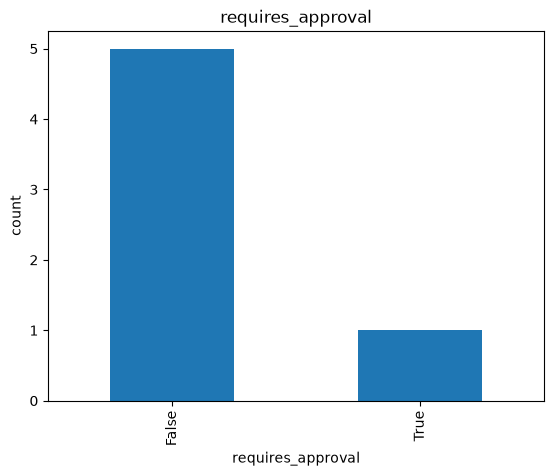

In [5]:
counts = df["requires_approval"].value_counts()
print(counts)
counts.plot(kind="bar", title="requires_approval")
plt.xlabel("requires_approval")
plt.ylabel("count")
plt.show()

## 3. Top 3 correlations
Boolean column converted to 0/1 so it can be correlated.

In [6]:
import numpy as np

num = df.select_dtypes(include=["number", "bool"]).astype(float)
corr = num.corr()

# keep only the upper triangle so each pair appears once
upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().sort_values(key=abs, ascending=False)
print(pairs.head(3))

step_id      requires_approval    0.654654
max_retries  requires_approval   -0.533114
step_id      max_retries          0.193892
dtype: float64


## 4. Missing values

In [7]:
missing_pct = df.isnull().mean() * 100
print(missing_pct)
print("Columns above 5% missing:", list(missing_pct[missing_pct > 5].index))

step_id              0.0
node                 0.0
description          0.0
next_node            0.0
condition            0.0
max_retries          0.0
requires_approval    0.0
dtype: float64
Columns above 5% missing: []
